# Analytical Models & Parameter Sweeps (`softpotato.analytical`)

## 1. Goal

Explore `softpotato.analytical` directly to perform rapid, vectorized parameter sweeps across transient (`cottrell`), voltammetric (`randles_sevcik`, `nicholson_psi`), hydrodynamic (`levich`, `koutecky_levich`), microelectrode (`microdisc_limiting_current`), and interfacial kinetic (`butler_volmer`) models.

## 2. Physical Setup

All functions in `softpotato.analytical` operate on NumPy scalars or arrays in **SI units** ($\text{m}$, $\text{s}$, $\text{mol/m}^3$, $\text{A}$, $\text{V}$). We define a shared set of baseline electrochemical parameters for a one-electron redox couple ($n = 1$, $T = 298.15\text{ K}$).

In [1]:
# !pip install -q softpotato

import matplotlib.pyplot as plt
import numpy as np

from softpotato import analytical as spa

# Baseline SI parameters
n = 1
T = 298.15            # Temperature [K]
c_bulk = 1.0          # Bulk concentration [mol/m^3] (= 1 mM)
D_ref = 1.0e-9        # Reference diffusivity [m^2/s]
r_disk = 1.5e-3       # Macro-disk radius [m] (3 mm diameter)
area = np.pi * r_disk**2
nu = 1.0e-6           # Kinematic viscosity of water [m^2/s]

## 3. Diffusivity Sweep: Cottrell & Randles–Ševčík Scaling

Both the Cottrell transient current ($I \propto D^{1/2} t^{-1/2}$) and the reversible CV peak current ($I_p \propto D^{1/2} v^{1/2}$) scale with $\sqrt{D}$. Vectorized array broadcasting makes multi-parameter sweeps instantaneous.

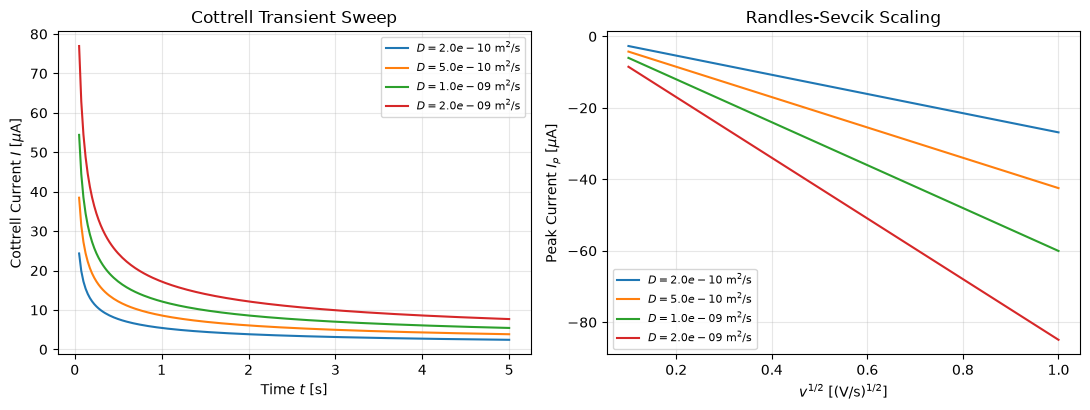

In [2]:
t = np.linspace(0.05, 5.0, 200)
v_sweep = np.linspace(0.01, 1.0, 100)
D_values = [2.0e-10, 5.0e-10, 1.0e-9, 2.0e-9]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

for D_val in D_values:
    i_cot = spa.cottrell(t, n=n, D=D_val, c_bulk=c_bulk, area=area)
    ip_rs = spa.randles_sevcik(v_sweep, c_bulk=c_bulk, D=D_val, area=area, n=n, T=T)
    label = rf"$D = {D_val:.1e}$ m$^2$/s"
    ax1.plot(t, i_cot * 1e6, label=label)
    ax2.plot(np.sqrt(v_sweep), ip_rs * 1e6, label=label)

ax1.set_xlabel("Time $t$ [s]")
ax1.set_ylabel(r"Cottrell Current $I$ [$\mu$A]")
ax1.set_title("Cottrell Transient Sweep")
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

ax2.set_xlabel(r"$v^{1/2}$ [$(\mathrm{V/s})^{1/2}$]")
ax2.set_ylabel(r"Peak Current $I_p$ [$\mu$A]")
ax2.set_title("Randles-Sevcik Scaling")
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

## 4. Hydrodynamic RDE Sweeps: Levich vs. Koutecký–Levich

At a rotating disk electrode (RDE), pure mass-transport control follows the **Levich equation** ($I_L \propto \omega^{1/2}$), whereas mixed kinetic–diffusion control follows the **Koutecký–Levich equation**:

$$
\frac{1}{I} = \frac{1}{I_k} + \frac{1}{I_L(\omega)}
$$

Below we sweep rotation rate $\text{rpm} \in [200, 3600]$ across several kinetic current limits $I_k$.

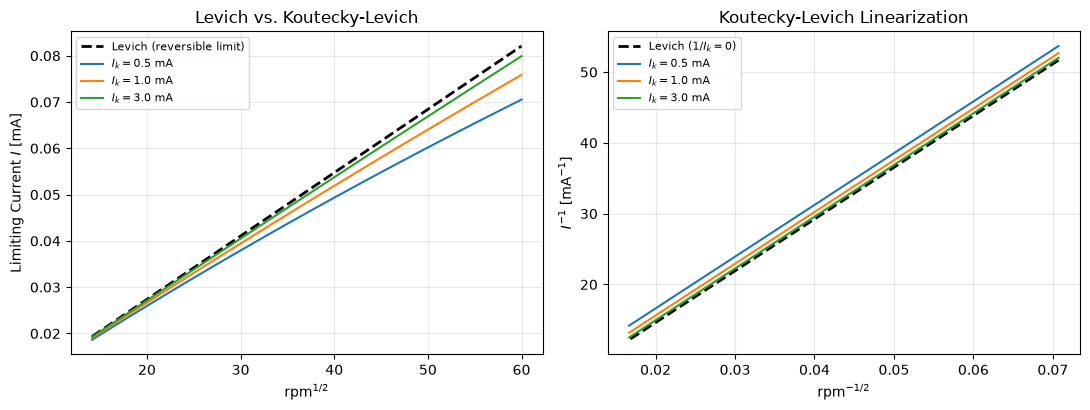

In [3]:
rpm = np.linspace(200, 3600, 80)
i_lev = spa.levich(rpm=rpm, n=n, D=D_ref, c_bulk=c_bulk, area=area, nu=nu)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ax1.plot(np.sqrt(rpm), i_lev * 1e3, "k--", lw=2, label="Levich (reversible limit)")
ax2.plot(1.0 / np.sqrt(rpm), 1.0 / (i_lev * 1e3), "k--", lw=2, label="Levich ($1/I_k = 0$)")

for i_k in [0.5e-3, 1.0e-3, 3.0e-3]:
    i_kl = spa.koutecky_levich(
        rpm=rpm, i_k=i_k, n=n, D=D_ref, c_bulk=c_bulk, area=area, nu=nu
    )
    lbl = rf"$I_k = {i_k*1e3:.1f}$ mA"
    ax1.plot(np.sqrt(rpm), i_kl * 1e3, label=lbl)
    ax2.plot(1.0 / np.sqrt(rpm), 1.0 / (i_kl * 1e3), label=lbl)

ax1.set_xlabel(r"$\mathrm{rpm}^{1/2}$")
ax1.set_ylabel("Limiting Current $I$ [mA]")
ax1.set_title("Levich vs. Koutecky-Levich")
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

ax2.set_xlabel(r"$\mathrm{rpm}^{-1/2}$")
ax2.set_ylabel(r"$I^{-1}$ [$\mathrm{mA}^{-1}$]")
ax2.set_title("Koutecky-Levich Linearization")
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

## 5. Microelectrode & Butler–Volmer Kinetic Sweeps

We also compare steady-state microdisc limiting currents ($I_{\text{ss}} = 4 n F D c^* r_0$) across electrode radii and Butler–Volmer current–overpotential curves across transfer coefficients $\alpha$.

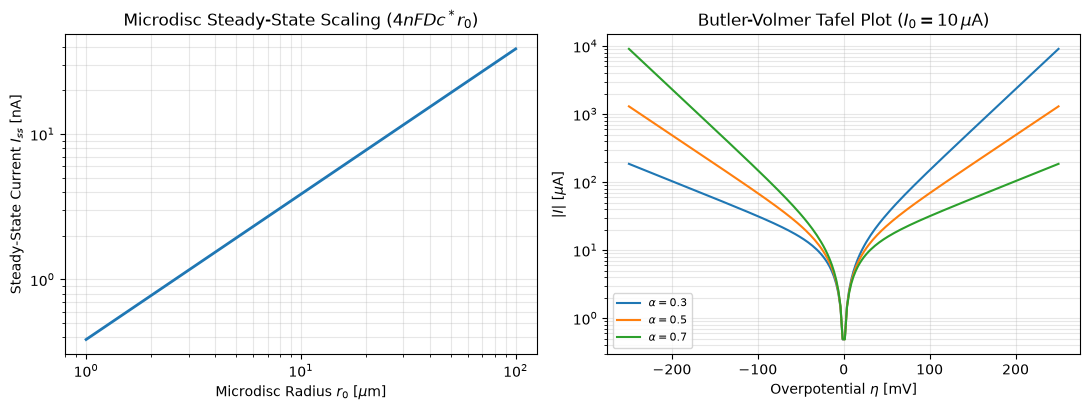

In [4]:
radii_um = np.logspace(0, 2, 100)  # 1 um to 100 um
i_ume = spa.microdisc_limiting_current(radii_um * 1e-6, n=n, D=D_ref, c_bulk=c_bulk)

eta = np.linspace(-0.25, 0.25, 200)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

ax1.loglog(radii_um, i_ume * 1e9, color="tab:blue", lw=2)
ax1.set_xlabel(r"Microdisc Radius $r_0$ [$\mu$m]")
ax1.set_ylabel("Steady-State Current $I_{ss}$ [nA]")
ax1.set_title("Microdisc Steady-State Scaling ($4nFDc^*r_0$)")
ax1.grid(True, which="both", alpha=0.3)

for alpha in [0.3, 0.5, 0.7]:
    i_bv = spa.butler_volmer(eta, i0=1.0e-5, alpha=alpha, n=n, T=T)
    ax2.semilogy(eta * 1e3, np.abs(i_bv) * 1e6, label=rf"$\alpha = {alpha}$")

ax2.set_xlabel(r"Overpotential $\eta$ [mV]")
ax2.set_ylabel(r"$|I|$ [$\mu$A]")
ax2.set_title(r"Butler-Volmer Tafel Plot ($I_0 = 10\,\mu\mathrm{A}$)")
ax2.legend(fontsize=8)
ax2.grid(True, which="both", alpha=0.3)

fig.tight_layout()
plt.show()

## Key Takeaways

- Every model in `softpotato.analytical` accepts NumPy arrays in SI units for instant vectorized parameter sweeps.
- Combining `levich()` and `koutecky_levich()` separates mass-transport and kinetic limitations across rotation rates.
- `microdisc_limiting_current()` and `butler_volmer()` provide fast analytical baselines for steady-state UMEs and interfacial kinetics.